In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

La matriz de incidencia $H$ del grafo PERT tiene una fila por arco (actividades y ficticias) y una columna por nodo, con −1 en el nodo origen del arco y +1 en el destino. Cada ruta es una cadena de arcos del nodo inicial al final. Considere el proyecto cuyo cuadro se adjunta.

In [4]:
pregunta_1 = "1. Dibuje el grafo PERT numerado y escriba la matriz de incidencia H (incluyendo las ficticias).  "
pregunta_2 = "2. Construya la matriz de rutas R *con* las ficticias (duración 0) y compruebe que R·H = 0 salvo en las columnas del nodo inicial y del final. ¿Por qué?  "
pregunta_3 = "3. Elija un vector y con un valor entero por nodo interior (0 en el inicial y el final) y defina la perturbación δ = H·y de las duraciones de los arcos. Compruebe que todas las rutas cambian de duración en la misma cantidad y que τ no cambia. Interprételo: ¿qué se ha hecho con los «tiempos de los nodos»?  "
pregunta_4 = "4. ¿Qué dimensión tiene el espacio de perturbaciones que dejan invariantes todas las duraciones de ruta? ¿Qué significa para la identificación de duraciones a partir de observaciones de rutas?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje el grafo PERT numerado y escriba la matriz de incidencia H (incluyendo las ficticias).  

2. Construya la matriz de rutas R *con* las ficticias (duración 0) y compruebe que R·H = 0 salvo en las columnas del nodo inicial y del final. ¿Por qué?  

3. Elija un vector y con un valor entero por nodo interior (0 en el inicial y el final) y defina la perturbación δ = H·y de las duraciones de los arcos. Compruebe que todas las rutas cambian de duración en la misma cantidad y que τ no cambia. Interprételo: ¿qué se ha hecho con los «tiempos de los nodos»?  

4. ¿Qué dimensión tiene el espacio de perturbaciones que dejan invariantes todas las duraciones de ruta? ¿Qué significa para la identificación de duraciones a partir de observaciones de rutas?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 7       ),
    ('B'     , '---'      , 4       ),
    ('C'     , 'A,B'      , 6       ),
    ('D'     , 'C'        , 7       ),
    ('E'     , 'D'        , 6       ),
    ('F'     , 'D'        , 8       ),
    ('G'     , 'E,F'      , 6       ),
    ('H'     , 'G'        , 4       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,7
B,---,4
C,"A,B",6
D,C,7
E,D,6
F,D,8
G,"E,F",6
H,G,4


# Resolución

In [6]:
def bmatrix(a, dec=0):
    """Matriz LaTeX (bmatrix) a partir de un DataFrame o array."""
    a = np.asarray(getattr(a, 'values', a), dtype=float)
    if a.ndim == 1:
        a = a.reshape(-1, 1)
    filas = [' & '.join(f'{x:.{dec}f}' for x in fila) + r'\\' for fila in a]
    return r'\begin{bmatrix}' + '\n' + '\n'.join(filas) + '\n' + r'\end{bmatrix}'

In [7]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Dibuje el grafo PERT numerado y escriba la matriz de incidencia H (incluyendo las ficticias).  

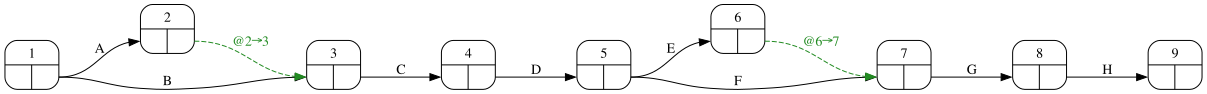

In [9]:
#| fig-cap: "Grafo PERT numerado"
#| label: fig-pert
proyecto.pert(durations=False, ranksep=1)

In [10]:
#| tbl-cap: "Matriz de incidencia H (arcos × nodos)"
#| label: tbl-H
H = proyecto.incidence_matrix()
H

,1,2,3,4,5,6,7,8,9
@2→3,0,-1,1,0,0,0,0,0,0
@6→7,0,0,0,0,0,-1,1,0,0
A,-1,1,0,0,0,0,0,0,0
B,-1,0,1,0,0,0,0,0,0
C,0,0,-1,1,0,0,0,0,0
D,0,0,0,-1,1,0,0,0,0
E,0,0,0,0,-1,1,0,0,0
F,0,0,0,0,-1,0,1,0,0
G,0,0,0,0,0,0,-1,1,0
H,0,0,0,0,0,0,0,-1,1


## Apartado 2

In [11]:
display(Markdown(pregunta_2))

2. Construya la matriz de rutas R *con* las ficticias (duración 0) y compruebe que R·H = 0 salvo en las columnas del nodo inicial y del final. ¿Por qué?  

In [12]:
R = proyecto.path_matrix(dummies=True)[H.index]
RH = R @ H
display(RH)
interiores = H.columns[1:-1]
Markdown(f'R·H es cero en las columnas interiores: {bool((RH[interiores] == 0).all().all())}; en la columna del nodo inicial vale {int(RH.iloc[0, 0])} y en la del final {int(RH.iloc[0, -1])} para todas las rutas.')

,1,2,3,4,5,6,7,8,9
Route_1,-1,0,0,0,0,0,0,0,1
Route_2,-1,0,0,0,0,0,0,0,1
Route_3,-1,0,0,0,0,0,0,0,1
Route_4,-1,0,0,0,0,0,0,0,1


R·H es cero en las columnas interiores: True; en la columna del nodo inicial vale -1 y en la del final 1 para todas las rutas.

Una ruta entra y sale de cada nodo interior exactamente una vez, así que la suma de sus entradas de incidencia es +1 − 1 = 0; sólo sale del inicial (−1) y sólo entra en el final (+1).

## Apartado 3

In [13]:
display(Markdown(pregunta_3))

3. Elija un vector y con un valor entero por nodo interior (0 en el inicial y el final) y defina la perturbación δ = H·y de las duraciones de los arcos. Compruebe que todas las rutas cambian de duración en la misma cantidad y que τ no cambia. Interprételo: ¿qué se ha hecho con los «tiempos de los nodos»?  

In [14]:
y_interior = {
    '2': -1,
    '3': 0,
    '4': -2,
    '5': -1,
    '6': -2,
    '7': 0,
    '8': -2,
}
y = pd.Series(0, index=H.columns, dtype=int)
for nodo, valor in y_interior.items():
    y[nodo] = valor
delta = H @ y
t = pd.Series({a: (datos_proyecto.loc[a, 'duration'] if not a.startswith('@') else 0) for a in H.index})
t_perturbado = t + delta
pd.DataFrame({'t': t, 'δ = H·y': delta, 't + δ': t_perturbado}).T

,@2→3,@6→7,A,B,C,D,E,F,G,H
t,0,0,7,4,6,7,6,8,6,4
δ = H·y,1,2,-1,0,-2,1,-1,1,-2,2
t + δ,1,2,6,4,4,8,5,9,4,6


In [15]:
Rt, Rt2 = R @ t, R @ t_perturbado
display(pd.DataFrame({'R·t': Rt, 'R·(t+δ)': Rt2, 'diferencia': Rt2 - Rt}))
Markdown(f'τ = {float(Rt.max()):.0f} antes y {float(Rt2.max()):.0f} después: las duraciones de todas las rutas cambian en {int((Rt2 - Rt).iloc[0])} (= y_final − y_inicial = 0), así que τ es invariante.')

,R·t,R·(t+δ),diferencia
Route_1,36,36,0
Route_2,38,38,0
Route_3,33,33,0
Route_4,35,35,0


τ = 38 antes y 38 después: las duraciones de todas las rutas cambian en 0 (= y_final − y_inicial = 0), así que τ es invariante.

δ = H·y añade a cada arco la diferencia de «potencial» entre su destino y su origen. Es lo mismo que mover el reloj de cada nodo: si al nodo j se le suma y_j a su tiempo, los arcos que llegan a j parecen y_j más largos y los que salen y_j más cortos, y a lo largo de cualquier ruta cerrada entre inicio y final todo se cancela. (Algunas duraciones perturbadas pueden salir negativas: es un ejercicio algebraico, no un calendario.)

## Apartado 4

In [16]:
display(Markdown(pregunta_4))

4. ¿Qué dimensión tiene el espacio de perturbaciones que dejan invariantes todas las duraciones de ruta? ¿Qué significa para la identificación de duraciones a partir de observaciones de rutas?  

In [17]:
N = proyecto.nullspace()
rango = np.linalg.matrix_rank(N.values)
Markdown(f'''Las columnas interiores de H generan un espacio de dimensión {rango} (número de nodos interiores, {N.shape[1]}) contenido en el núcleo de R. Hay por tanto {rango} direcciones independientes en las que pueden moverse las duraciones de los {len(t)} arcos sin que ninguna ruta cambie. Consecuencia: observando sólo duraciones de rutas no pueden identificarse las duraciones de los arcos; sólo se identifican módulo esas {rango} direcciones.''')

Las columnas interiores de H generan un espacio de dimensión 7 (número de nodos interiores, 7) contenido en el núcleo de R. Hay por tanto 7 direcciones independientes en las que pueden moverse las duraciones de los 10 arcos sin que ninguna ruta cambie. Consecuencia: observando sólo duraciones de rutas no pueden identificarse las duraciones de los arcos; sólo se identifican módulo esas 7 direcciones.